<a href="https://colab.research.google.com/github/valeencamargo14/TP-Labo-/blob/Tincho/TP_Labo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **3.1. Carga y exploración inicial**

### 3.1.a) Carga de datos y librerías
**Qué se hace:** Importamos las librerías `pandas`, `matplotlib` y `seaborn`, y cargamos los dos archivos CSV en DataFrames. Mostramos las primeras y últimas filas.
**Por qué:** `pandas` es el motor que nos permite estructurar y manipular los datos tabulares. Los archivos CSV son de elaboración propia, construidos mediante extracción (*web scraping*) desde Transfermarkt. Visualizar las cabeceras y colas nos permite confirmar que la lectura de nuestra base de datos fue exitosa y que las columnas se alinearon correctamente antes de empezar a operar.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar los datasets
df_posiciones = pd.read_csv('/content/premier_league_posiciones_2005_2026.csv')
df_gastos = pd.read_csv('/content/premier_league_gastos_2005_2026.csv')

# Mostrar las primeras filas de cada DataFrame
print("--- Posiciones ---")
print(df_posiciones.head(10))
print(df_posiciones.tail(10))

print("\n--- Gastos ---")
print(df_gastos.head(10))
print(df_gastos.tail(10))

--- Posiciones ---
  temporada                    club  posicion  puntos  partidos  ganados  \
0   2025-26              Arsenal FC         1      85        38       26   
1   2025-26         Manchester City         2      78        38       23   
2   2025-26       Manchester United         3      71        38       20   
3   2025-26             Aston Villa         4      65        38       19   
4   2025-26            Liverpool FC         5      60        38       17   
5   2025-26         AFC Bournemouth         6      57        38       13   
6   2025-26          Sunderland AFC         7      54        38       14   
7   2025-26  Brighton & Hove Albion         8      53        38       14   
8   2025-26            Brentford FC         9      53        38       14   
9   2025-26              Chelsea FC        10      52        38       14   

   empatados  perdidos  goles_favor  goles_contra  dif_goles  
0          7         5           71            27         44  
1          9      

### 3.1.b) Estructura de los Datasets
**Qué se hace:** Revisamos las dimensiones (`shape`), los tipos de datos de cada columna (`info`) y el rango temporal. Ejecutaremos esto primero para la tabla de posiciones y luego para la de gastos.
**Por qué:** Para poder hacer cálculos matemáticos o cruzar ambas tablas, necesitamos confirmar que la computadora entiende las columnas numéricas como números (`int64` o `float64`) y no como texto (`object`). Además, verificamos que ambos archivos abarquen exactamente el mismo marco temporal para no perder datos al unirlos.

In [2]:
# Estructura del dataset de Posiciones
print("=== ESTRUCTURA DE POSICIONES ===")
print(f"Dimensiones: {df_posiciones.shape}")
print("\nInformación general y tipos de datos:")
df_posiciones.info()
print(f"\nCobertura temporal (Temporadas): {df_posiciones['temporada'].nunique()} temporadas desde {df_posiciones['temporada'].min()} hasta {df_posiciones['temporada'].max()}")

=== ESTRUCTURA DE POSICIONES ===
Dimensiones: (420, 11)

Información general y tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   temporada     420 non-null    object
 1   club          420 non-null    object
 2   posicion      420 non-null    int64 
 3   puntos        420 non-null    int64 
 4   partidos      420 non-null    int64 
 5   ganados       420 non-null    int64 
 6   empatados     420 non-null    int64 
 7   perdidos      420 non-null    int64 
 8   goles_favor   420 non-null    int64 
 9   goles_contra  420 non-null    int64 
 10  dif_goles     420 non-null    int64 
dtypes: int64(9), object(2)
memory usage: 36.2+ KB

Cobertura temporal (Temporadas): 21 temporadas desde 2005-06 hasta 2025-26


In [3]:
# Estructura del dataset de Gastos
print("=== ESTRUCTURA DE GASTOS ===")
print(f"Dimensiones: {df_gastos.shape}")
print("\nInformación general y tipos de datos:")
df_gastos.info()
print(f"\nCobertura temporal (Temporadas): {df_gastos['temporada'].nunique()} temporadas desde {df_gastos['temporada'].min()} hasta {df_gastos['temporada'].max()}")

=== ESTRUCTURA DE GASTOS ===
Dimensiones: (420, 8)

Información general y tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   temporada    420 non-null    object 
 1   club         420 non-null    object 
 2   gasto_bruto  420 non-null    float64
 3   altas        420 non-null    int64  
 4   ingresos     420 non-null    float64
 5   bajas        420 non-null    int64  
 6   balance      420 non-null    float64
 7   gasto_neto   420 non-null    float64
dtypes: float64(4), int64(2), object(2)
memory usage: 26.4+ KB

Cobertura temporal (Temporadas): 21 temporadas desde 2005-06 hasta 2025-26


### 3.1.c) Calidad de los Datos y Estadísticas Descriptivas
Evaluaremos la presencia de valores nulos, registros duplicados y generaremos las estadísticas descriptivas.

**Qué se hace:** Contamos la cantidad de valores nulos (`isnull().sum()`), verificamos si hay registros repetidos (`duplicated()`) y generamos las estadísticas descriptivas básicas con `describe()`.
**Por qué:** Es un paso de diagnóstico crítico. Si tuviéramos celdas vacías o clubes duplicados en una misma temporada, cualquier cálculo posterior de rentabilidad estaría sesgado o rompería el código al intentar cruzar las tablas. El resumen estadístico nos permite entender rápidamente las "reglas del juego" (cuál es el máximo histórico de gasto, cuál es la media de puntos) antes de graficar.

In [4]:
# Análisis de calidad para Posiciones
print("=== CALIDAD Y ESTADÍSTICAS EN POSICIONES ===")
print(f"Valores nulos por columna:\n{df_posiciones.isnull().sum()}")
print(f"\nCantidad de filas duplicadas: {df_posiciones.duplicated().sum()}")
print("\nEstadísticas descriptivas:")
print(df_posiciones.describe())

=== CALIDAD Y ESTADÍSTICAS EN POSICIONES ===
Valores nulos por columna:
temporada       0
club            0
posicion        0
puntos          0
partidos        0
ganados         0
empatados       0
perdidos        0
goles_favor     0
goles_contra    0
dif_goles       0
dtype: int64

Cantidad de filas duplicadas: 0

Estadísticas descriptivas:
         posicion      puntos  partidos     ganados   empatados    perdidos  \
count  420.000000  420.000000     420.0  420.000000  420.000000  420.000000   
mean    10.500000   52.328571      38.0   14.378571    9.242857   14.378571   
std      5.773158   17.653970       0.0    6.127291    2.830632    5.788394   
min      1.000000   11.000000      38.0    1.000000    2.000000    1.000000   
25%      5.750000   40.000000      38.0   10.000000    7.000000   10.000000   
50%     10.500000   49.000000      38.0   13.000000    9.000000   15.000000   
75%     15.250000   64.250000      38.0   18.250000   11.000000   19.000000   
max     20.000000  100.0

In [5]:
# Análisis de calidad para Gastos
print("=== CALIDAD Y ESTADÍSTICAS EN GASTOS ===")
print(f"Valores nulos por columna:\n{df_gastos.isnull().sum()}")
print(f"\nCantidad de filas duplicadas: {df_gastos.duplicated().sum()}")
print("\nEstadísticas descriptivas:")
print(df_gastos.describe())

=== CALIDAD Y ESTADÍSTICAS EN GASTOS ===
Valores nulos por columna:
temporada      0
club           0
gasto_bruto    0
altas          0
ingresos       0
bajas          0
balance        0
gasto_neto     0
dtype: int64

Cantidad de filas duplicadas: 0

Estadísticas descriptivas:
       gasto_bruto       altas    ingresos      bajas     balance  gasto_neto
count   420.000000  420.000000  420.000000  420.00000  420.000000  420.000000
mean     78.409000   24.504762   40.089726   22.10000  -38.320021   38.320021
std      76.431008    8.545958   50.135842    7.22958   61.753791   61.753791
min       0.000000    5.000000    0.000000    4.00000 -562.390000 -129.310000
25%      25.825000   18.000000    5.597500   17.00000  -59.675000    5.757500
50%      55.010000   23.000000   23.730000   21.50000  -23.220000   23.220000
75%     107.037500   30.000000   53.827500   27.00000   -5.757500   59.675000
max     630.250000   57.000000  339.250000   48.00000  129.310000  562.390000


### 3.1.c) Coherencia Interna de los Datos
Evaluaremos si las columnas calculadas de cada tabla son consistentes con las columnas de las que se derivan, y si hay puntos que no coinciden con los resultados de los partidos.

**Qué se hace:** Verificamos que `balance` sea igual a `ingresos - gasto_bruto` (con una tolerancia de 0.05 por redondeos), que `dif_goles` sea `goles_favor - goles_contra`, que `ganados + empatados + perdidos` sumen los `partidos` jugados, que los puntos coincidan con `3 * ganados + empatados` y que, en cada temporada, la suma de goles a favor sea igual a la de goles en contra.
**Por qué:** Como los archivos CSV son de elaboración propia, conviene comprobar que los números no se contradigan entre sí. Si una columna derivada no coincide con las columnas que la componen, puede haber un error de carga o de transcripción que contamine los análisis posteriores.

In [6]:
# 2) Coherencia interna
dif_balance = (df_gastos['ingresos'] - df_gastos['gasto_bruto'] - df_gastos['balance']).abs()
print(f'balance distinto de ingresos - gasto_bruto: {(dif_balance > 0.05).sum()} filas')

print(f"\ndif_goles distinto de goles_favor - goles_contra: "
      f"{(df_posiciones['goles_favor'] - df_posiciones['goles_contra'] != df_posiciones['dif_goles']).sum()} filas")
print(f"ganados + empatados + perdidos distinto de partidos: "
      f"{(df_posiciones['ganados'] + df_posiciones['empatados'] + df_posiciones['perdidos'] != df_posiciones['partidos']).sum()} filas")

esperado = 3 * df_posiciones['ganados'] + df_posiciones['empatados']
print('\nFilas donde puntos != 3*ganados + empatados (sanciones):')
display(df_posiciones[df_posiciones['puntos'] != esperado]
        [['temporada', 'club', 'ganados', 'empatados', 'puntos']].assign(esperado=esperado))

goles = df_posiciones.groupby('temporada')[['goles_favor', 'goles_contra']].sum()
print(f'Temporadas donde la suma de goles a favor y en contra no coincide: {(goles.goles_favor != goles.goles_contra).sum()}')

balance distinto de ingresos - gasto_bruto: 0 filas

dif_goles distinto de goles_favor - goles_contra: 0 filas
ganados + empatados + perdidos distinto de partidos: 0 filas

Filas donde puntos != 3*ganados + empatados (sanciones):


,temporada,club,ganados,empatados,puntos,esperado
54,2023-24,Everton FC,13,9,40,48
56,2023-24,Nottingham Forest,9,9,32,36
339,2009-10,Portsmouth FC,7,7,19,28


Temporadas donde la suma de goles a favor y en contra no coincide: 0


**Resultado:** Todas las comprobaciones dieron 0 filas inconsistentes, salvo una: hay tres filas donde los puntos no coinciden con 3 por victoria más empates, y son sanciones reales de deducción de puntos a los siguientes equipos:
*   Everton 2023-24: 40 puntos, en lugar de 48.
*   Nottingham Forest 2023-24: 32 puntos, en lugar de 36.
*   Portsmouth 2009-10: 19 puntos, en lugar de 28.

### 3.1.c) Gasto Bruto y Gasto Neto por Temporada
Calcularemos el gasto total de la liga en cada temporada, desde 2005-06 hasta 2025-26.

**Qué se hace:** Con `groupby('temporada')` agrupamos las filas de `df_gastos` por temporada y sumamos `gasto_bruto` y `gasto_neto` de los 20 clubes, obteniendo un total de la liga para cada una de las 21 temporadas (de 2005-06 a 2025-26). Todos los montos están en millones de euros.
**Por qué:** El gasto de cada club por separado no permite ver cómo cambió el mercado de pases a lo largo del tiempo. Agregar por temporada muestra la evolución del dinero que mueve la liga y deja ver si los montos de épocas distintas son comparables, algo clave para nuestra comparación entre 2005-06 y 2025-26.

In [7]:
# Gasto bruto y gasto neto por temporada (suma de los 20 clubes de cada temporada)
gasto_bruto_temporada = df_gastos.groupby('temporada')['gasto_bruto'].sum().round(2)
gasto_neto_temporada = df_gastos.groupby('temporada')['gasto_neto'].sum().round(2)

print("=== GASTO BRUTO POR TEMPORADA (millones de €) ===")
display(gasto_bruto_temporada.to_frame())

print("\n=== GASTO NETO POR TEMPORADA (millones de €) ===")
display(gasto_neto_temporada.to_frame())

=== GASTO BRUTO POR TEMPORADA (millones de €) ===


,gasto_bruto
temporada,
2005-06,505.45
2006-07,536.59
2007-08,940.52
2008-09,858.37
2009-10,585.28
2010-11,701.33
2011-12,643.30
2012-13,775.04
2013-14,924.41



=== GASTO NETO POR TEMPORADA (millones de €) ===


,gasto_neto
temporada,
2005-06,268.55
2006-07,290.45
2007-08,466.82
2008-09,327.19
2009-10,75.00
2010-11,357.59
2011-12,215.90
2012-13,402.51
2013-14,519.24


**Resultado:** El gasto bruto total pasa de 505.45 millones en 2005-06 a 4061.22 millones en 2025-26, y el gasto neto total pasa de 268.55 a 1633.14 millones.

### ***Interpretación de la Exploración Inicial***

**1. Calidad e Integridad de los Datos**

Ambos conjuntos de datos cuentan con exactamente 420 registros (que corresponden a 20 equipos analizados a lo largo de 21 temporadas). La revisión confirma que no existen valores nulos ni filas duplicadas en ninguna de las tablas. Esto garantiza que las bases son estructuralmente sólidas: no será necesario aplicar técnicas de imputación de datos ni eliminar registros defectuosos antes de realizar el cruce relacional entre lo deportivo y lo financiero.  

**2. Comportamiento de las Variables Deportivas (Posiciones)**

*   **Brecha de Puntos:** La liga exhibe una enorme dispersión competitiva. Mientras que el mejor registro histórico alcanzó los 100 puntos, la peor campaña sumó apenas 11 puntos tras 38 partidos. La mediana se sitúa en 49 puntos, marcando la barrera estadística típica de la mitad de la tabla.

*   **Rendimiento en la red:** Un equipo promedio marca y recibe unos 52 goles por temporada. Sin embargo, los extremos de la muestra (mínimo de 20 goles a favor frente a un máximo de 106) sugieren que analizaremos equipos con capacidades ofensivas radicalmente distintas.

**3. Comportamiento de las Variables Financieras (Gastos)**

*   **Gasto Neto (Nuestra variable central):** El rango varía desde un mínimo de -129.31 millones hasta un máximo de 562.39 millones. En términos económicos, los valores negativos representan superávit financiero (el club ingresó más dinero por ventas del que invirtió en compras), mientras que los valores positivos altos reflejan una inyección de capital masiva en contrataciones.

*   **Asimetría en la inversión:** El 75% de los equipos presenta un gasto neto inferior a 59.67 millones, pero el máximo supera los 560 millones. Esta concentración del gasto en un grupo reducido de clubes justifica nuestra investigación: evaluaremos si esta profunda desigualdad financiera condiciona directamente el éxito deportivo.

### 3.2. Pregunta de Investigación

**a) ¿Cuál es la pregunta?**
¿Cuál es el impacto del gasto neto en el mercado de pases sobre la posición final en la tabla de la Premier League, y cómo cambió cuánto se parece el orden de gasto al orden de la tabla al contrastar exclusivamente las temporadas 2005-06 y 2025-26?

**b) ¿Por qué vale la pena responderla?**
Este análisis ilumina el fenómeno de la hipercomercialización del deporte y aborda un problema central en la gestión de organizaciones deportivas: *¿es el fútbol moderno un ecosistema donde el éxito está estrictamente predeterminado por el presupuesto inicial?*

Vale la pena responderla porque contrastar estas dos temporadas específicas (con una brecha exacta de 20 años) expone un evidente cambio de paradigma. La temporada **2005-06** representa la consolidación de la primera gran inyección de capitales privados en Inglaterra (ej. el Chelsea de Román Abramóvich), mientras que la temporada finalizada en mayo de **2025-26** muestra el panorama actual hiperinflacionado, dominado por clubes-estado y regulado por normativas de *Fair Play* financiero.

El análisis permitirá descubrir si la eficiencia en el *scouting* y la gestión de equipos todavía pueden quebrar el vínculo entre dinero y puntos, o si la brecha financiera se volvió insalvable.

**c) ¿Qué respuesta encontraron?**
El gasto neto **sigue asociado a la posición final, pero no la decide**, y el vínculo fue algo más flojo en 2025-26 que en 2005-06, aunque el dinero que se mueve en el mercado de pases creció enormemente (el gasto bruto total de la liga se multiplicó por 8 y el gasto neto total por 6).

* **2005-06:** el orden de gasto y el orden de la tabla estuvieron muy parecidos: en promedio, cada club terminó a solo **4.1 puestos** de donde lo ubicaba su gasto (la diferencia más chica de las 21 temporadas). El campeón, Chelsea, fue además el club con mayor gasto neto.
* **2025-26:** la diferencia promedio fue de **5.3 puestos**, cerca del promedio de la serie (5.8). Hubo clubes con mucho gasto neto que terminaron mal (Tottenham, 4º en gasto y 17º en la tabla) y clubes con superávit que terminaron arriba (Bournemouth, 6º, con -129.3 millones). Aun así, el campeón, Arsenal, fue otra vez el mayor gastador.
* **Dinero vs. resultado:** el gasto neto promedio del Top 4 por encima del de los clubes en zona de descenso pasó de unos 26 a unos 145 millones. La brecha en dinero se amplió muchísimo, pero los dos extremos se parecen: en las dos temporadas, 2 de los 4 clubes que más gastaron terminaron Top 4.
* **Las 21 temporadas:** de los 4 que más gastaron, en promedio 1.5 terminaron Top 4 (por puro azar serían 0.8), y el campeón fue el mayor gastador en solo 4 de 21 temporadas.
* **Largo plazo:** el gasto de una sola temporada alcanza poco, pero el gasto **sostenido durante 21 años** sí distingue a los grandes: los 6 clubes que más gastaron en neto son también los 6 con mejor posición promedio.

Con estos datos **no encontramos evidencia** de que el gasto neto haya pasado a determinar la tabla con más fuerza que hace 20 años. Una explicación posible es que otros factores (salarios, plantel acumulado, gestión deportiva) pesen más hoy, pero este dataset no permite comprobarlo.

**Cautelas:**
1. La diferencia entre 4.1 y 5.3 puestos es chica y con solo 20 clubes por temporada no alcanza para afirmar un cambio real.
2. Comparar solo dos temporadas exagera el cambio: 2005-06 es la temporada donde el gasto y la tabla estuvieron más alineados de las 21, mientras que 2025-26 es una temporada típica (gráfico 3.5.b). No hay una tendencia clara en el tiempo.
3. Es una asociación, no una causalidad: el gasto neto de una temporada no incluye los salarios ni el valor del plantel acumulado en años anteriores.

### 3.3. Transformaciones y resumen estadístico

### 3.3.a) Transformaciones de Datos
**Qué se hace:** Aplicamos cuatro transformaciones sobre los datos:
1. **Unión de tablas (`pd.merge()`):** unimos el DataFrame de posiciones con el de gastos usando `temporada` y `club` como claves de cruce, y comprobamos que la cantidad de filas no cambie.
2. **Filtrado de filas:** filtramos el dataset resultante para quedarnos *únicamente* con los datos de las temporadas 2005-06 y 2025-26.
3. **Columna derivada `costo_por_punto`:** generamos una nueva métrica (Gasto Neto / Puntos).
4. **Columna derivada `grupo_tabla` (`pd.cut()`):** convertimos la posición final (del 1 al 20) en tres categorías: Top 4 (puestos 1 a 4), Media tabla (5 a 17) y Descenso (18 a 20).

**Por qué:**
1. La unión relacional es indispensable porque necesitamos que el rendimiento en la cancha (puntos/posición) conviva en la misma fila con la inversión financiera (gasto neto) para cada club. Contar las filas antes y después es una buena práctica para asegurarnos de que el `merge` no haga desaparecer clubes sin avisar.
2. El filtrado responde directamente a nuestra pregunta de investigación, descartando el ruido de los 19 años intermedios.
3. El costo por punto nos da una métrica de "eficiencia deportiva" que penaliza a los equipos que gastan mucho para sumar poco. Cuando el gasto neto es negativo (el club vendió más de lo que compró), el valor es negativo y se interpreta como superávit.
4. Una posición del 1 al 20 sirve para ordenar a los clubes, pero no para comparar categorías. Agrupar la tabla en zonas (los cuatro primeros, que históricamente clasifican a la Champions League; la zona de descenso, los últimos tres; y el resto) nos permite comparar el gasto entre clubes de arriba, del medio y de abajo en el gráfico 3.4.b.

In [8]:
# 1. Primera transformación: Unión de las tablas (Merge)
df_completo = pd.merge(df_posiciones, df_gastos, on=['temporada', 'club'], how='inner')
print(f"Filas antes del merge: posiciones = {len(df_posiciones)}, gastos = {len(df_gastos)} | después del merge: {len(df_completo)}")

# 2. Segunda transformación: Filtrado temporal
df_estudio = df_completo[df_completo['temporada'].isin(['2005-06', '2025-26'])].copy()

# 3. Tercera transformación: Columna derivada (Costo por Punto)
df_estudio['costo_por_punto'] = round(df_estudio['gasto_neto'] / df_estudio['puntos'], 2)

# 4. Cuarta transformación: Columna derivada (grupo de la tabla según la posición final)
df_estudio['grupo_tabla'] = pd.cut(df_estudio['posicion'], bins=[0, 4, 17, 20],
                                   labels=['Top 4 (1-4)', 'Media tabla (5-17)', 'Descenso (18-20)'])

print(f"Dimensiones del nuevo dataset de estudio: {df_estudio.shape}")

print("\n--- Ejemplo de temporada 2005-06 ---")
display(df_estudio[df_estudio['temporada'] == '2005-06'].head(3))

print("\n--- Ejemplo de temporada 2025-26 ---")
display(df_estudio[df_estudio['temporada'] == '2025-26'].head(3))

Filas antes del merge: posiciones = 420, gastos = 420 | después del merge: 420
Dimensiones del nuevo dataset de estudio: (40, 19)

--- Ejemplo de temporada 2005-06 ---


,temporada,club,posicion,puntos,partidos,ganados,empatados,perdidos,goles_favor,goles_contra,dif_goles,gasto_bruto,altas,ingresos,bajas,balance,gasto_neto,costo_por_punto,grupo_tabla
400,2005-06,Chelsea FC,1,91,38,29,4,5,72,22,50,91.50,19,34.60,19,-56.90,56.90,0.63,Top 4 (1-4)
401,2005-06,Manchester United,2,83,38,25,8,5,72,34,38,31.80,25,7.90,27,-23.90,23.90,0.29,Top 4 (1-4)
402,2005-06,Liverpool FC,3,82,38,25,7,6,57,25,32,44.06,29,19.04,26,-25.02,25.02,0.31,Top 4 (1-4)



--- Ejemplo de temporada 2025-26 ---


,temporada,club,posicion,puntos,partidos,ganados,empatados,perdidos,goles_favor,goles_contra,dif_goles,gasto_bruto,altas,ingresos,bajas,balance,gasto_neto,costo_por_punto,grupo_tabla
0,2025-26,Arsenal FC,1,85,38,26,7,5,71,27,44,297.57,21,13.88,17,-283.69,283.69,3.34,Top 4 (1-4)
1,2025-26,Manchester City,2,78,38,23,9,6,77,35,42,301.80,26,107.28,20,-194.52,194.52,2.49,Top 4 (1-4)
2,2025-26,Manchester United,3,71,38,20,11,7,69,50,19,246.70,18,77.20,14,-169.50,169.50,2.39,Top 4 (1-4)


**Resultado:** el `merge` conserva las 420 filas: cada combinación club-temporada de la tabla de posiciones tiene su par en la tabla de gastos, así que no se pierde ningún dato. El dataset de estudio queda con 40 filas (20 clubes × 2 temporadas) y 19 columnas: las 17 del cruce más las dos columnas nuevas, `costo_por_punto` y `grupo_tabla`.

### 3.3.b) Resumen estadístico agrupado (`groupby`)
**Qué se hace:** Calculamos tres estadísticos agrupados con `groupby()` sobre `df_estudio`:
1. El gasto neto (cantidad de clubes, promedio y mediana) por temporada y por grupo de la tabla.
2. Qué tan parecido es el orden de gasto al orden de la tabla, temporada por temporada: cuántos de los 4 clubes que más gastaron terminaron Top 4, en qué puesto terminaron en promedio los 5 que más gastaron, en qué puesto de gasto estaba el campeón y cuántos puestos separan, en promedio, el puesto de gasto de cada club de su puesto en la tabla.
3. El costo por punto (promedio, mediana, mínimo y máximo) por temporada.

**Por qué:** La pregunta de investigación quiere medir el impacto del gasto neto sobre la posición y cómo cambió esa relación entre 2005-06 y 2025-26. El primer estadístico muestra si los clubes de arriba gastan más que los de abajo. El segundo mide, con números fáciles de leer, cuánto se parece el ranking de gasto al ranking de la tabla y lo compara con lo que pasaría por puro azar (por ejemplo, por azar solo 0.8 de los 4 que más gastan terminarían Top 4). Rankear dentro de cada temporada evita el problema de la inflación: importa quién gastó más que los demás ese año, no los euros absolutos. El tercero usa la columna `costo_por_punto` que creamos para comparar la eficiencia entre las dos épocas.

In [9]:
# Estadístico 1: gasto neto por temporada y grupo de la tabla
resumen_grupos = (df_estudio.groupby(['temporada', 'grupo_tabla'], observed=True)['gasto_neto']
                  .agg(clubes='count', promedio='mean', mediana='median').round(1))
print("=== GASTO NETO POR GRUPO DE LA TABLA (millones de €) ===")
display(resumen_grupos)

# Estadístico 3: costo por punto por temporada
resumen_costo = df_estudio.groupby('temporada')['costo_por_punto'].agg(['mean', 'median', 'min', 'max']).round(2)
print("\n=== COSTO POR PUNTO POR TEMPORADA (millones de € por punto) ===")
display(resumen_costo)

=== GASTO NETO POR GRUPO DE LA TABLA (millones de €) ===


clubes  promedio  mediana
temporada grupo_tabla                                  
2005-06   Top 4 (1-4)              4      31.7     24.5
          Media tabla (5-17)      13       9.6     10.1
          Descenso (18-20)         3       5.5      6.0
2025-26   Top 4 (1-4)              4     168.3    182.0
          Media tabla (5-17)      13      68.3    102.8
          Descenso (18-20)         3      23.8     56.3


=== COSTO POR PUNTO POR TEMPORADA (millones de € por punto) ===


,mean,median,min,max
temporada,,,,
2005-06,0.23,0.22,-0.47,0.63
2025-26,1.44,2.18,-4.06,4.46


In [10]:
import numpy as np

# Estadístico 2: ¿qué tan parecido es el orden de gasto al orden de la tabla? (medidas simples)
# Puesto de cada club según su gasto neto dentro de su temporada (1 = el que más gastó)
df_completo['rank_gasto'] = (df_completo.groupby('temporada')['gasto_neto']
                             .rank(ascending=False, method='min').astype(int))

filas = []
for temporada, d in df_completo.groupby('temporada'):
    top5_gasto = d[d['rank_gasto'] <= 5]
    campeon = d[d['posicion'] == 1].iloc[0]
    filas.append({
        'temporada': temporada,
        'aciertos_top4': int(((d['rank_gasto'] <= 4) & (d['posicion'] <= 4)).sum()),   # de los 4 que más gastaron, cuántos quedaron Top 4
        'pos_prom_top5_gasto': round(top5_gasto['posicion'].mean(), 1),               # posición promedio de los 5 que más gastaron
        'brecha_prom': round((d['rank_gasto'] - d['posicion']).abs().mean(), 1),      # puestos de diferencia, en promedio, entre gasto y tabla
        'campeon': campeon['club'],
        'rank_gasto_campeon': int(campeon['rank_gasto']),                             # puesto de gasto del campeón
    })
medidas = pd.DataFrame(filas).set_index('temporada')

print("=== MEDIDAS SIMPLES DE LAS DOS TEMPORADAS DE LA PREGUNTA ===")
display(medidas.loc[['2005-06', '2025-26']])
print("Referencia por azar: 0.8 aciertos, posición promedio de los 5 que más gastan = 10.5, brecha promedio = 6.7 puestos")

=== MEDIDAS SIMPLES DE LAS DOS TEMPORADAS DE LA PREGUNTA ===


,aciertos_top4,pos_prom_top5_gasto,brecha_prom,campeon,rank_gasto_campeon
temporada,,,,,
2005-06,2,4.8,4.1,Chelsea FC,1
2025-26,2,5.6,5.3,Arsenal FC,1


Referencia por azar: 0.8 aciertos, posición promedio de los 5 que más gastan = 10.5, brecha promedio = 6.7 puestos


**Interpretación:**
* **Gasto neto por grupo de la tabla.** En las dos temporadas, cuanto mejor es el grupo, más gasta en neto: Top 4 > Media tabla > Descenso. En 2005-06 el Top 4 gastó en promedio 31.7 millones contra 5.5 de los clubes en zona de descenso; en 2025-26, 168.3 contra 23.8. La brecha en dinero pasó de unos 26 a unos 145 millones. En términos relativos, en cambio, la ventaja de los de arriba no creció: el Top 4 gastó 3.3 veces lo que la media tabla en 2005-06 (31.7 vs. 9.6) y 2.5 veces en 2025-26 (168.3 vs. 68.3).
* **Qué tan parecido es el orden de gasto al orden de la tabla.** En 2005-06 cada club terminó, en promedio, a 4.1 puestos de donde lo ubicaba su gasto; en 2025-26, a 5.3 puestos. Si el gasto no tuviera ninguna relación con la tabla, la diferencia sería de unos 6.7 puestos, así que en las dos temporadas el gasto se parece al orden de la tabla, algo más en 2005-06 (que es la temporada más alineada de las 21). En ambas, 2 de los 4 clubes que más gastaron terminaron Top 4 (Chelsea y Liverpool en 2005-06; Arsenal y Manchester City en 2025-26). Es la evidencia central para nuestra pregunta: el vínculo se aflojó un poco, pero no desapareció.
* **Costo por punto.** El promedio pasó de 0.23 a 1.44 millones por punto (la mediana, de 0.22 a 2.18), unas 6 veces más, reflejo de la inflación del mercado que vemos en el gráfico 3.4.a. Además, los clubes con costo negativo (superávit: vendieron más de lo que compraron) pasaron de 1 en 2005-06 a 5 en 2025-26, lo que muestra que hoy hay más clubes que financian su plantel vendiendo jugadores.

### 3.4. Análisis gráfico
Producimos tres gráficos de tipos distintos (los mínimos que pide la consigna). En la sección 3.5 se suman gráficos complementarios de contexto. Cada uno lleva título, etiquetas en ambos ejes, una celda de interpretación y se exporta como imagen con `plt.savefig()` para incluirlo en el informe.

| Gráfico | Tipo | Qué muestra | Por qué ese tipo |
|---|---|---|---|
| **3.4.a** | Líneas (evolución temporal) | Gasto bruto y gasto neto total de la liga, 2005-06 a 2025-26 | Una serie en el tiempo se lee mejor como línea; da el contexto de inflación del mercado |
| **3.4.b** | Barras agrupadas (comparación entre categorías) | Gasto neto promedio de los clubes del Top 4, de la media tabla y del descenso, en 2005-06 y 2025-26 | Compara categorías por la altura de la barra |
| **3.4.c** | Dispersión (relación entre dos variables) | Gasto neto vs. posición final de cada club, una por temporada | Responde directamente la pregunta: muestra la relación club por club |

**Qué se hace:** Definimos el estilo y los colores que usan todos los gráficos.
**Por qué:** Usar el mismo estilo en todos mantiene el informe coherente.

In [11]:
sns.set_theme(style="whitegrid")                                           # estilo de los gráficos
AZUL, NARANJA, ROJO, VERDE = "#243b5e", "#e07b39", "#b03a2e", "#2e8b57"    # paleta de colores

### 3.4.a) Evolución temporal del gasto
**Tipo de gráfico:** líneas (serie temporal).
**Qué se hace:** Dibujamos el gasto bruto total y el gasto neto total de la liga a lo largo de las 21 temporadas (de 2005-06 a 2025-26), usando las series que calculamos con `groupby` en 3.1.c. Marcamos con líneas punteadas las dos temporadas que contrasta la pregunta.
**Por qué:** Para entender si la relación entre dinero y posición cambió entre 2005-06 y 2025-26, primero hay que conocer el contexto: cuánto se encareció el mercado y si las dos temporadas elegidas son puntos de quiebre o extremos de la serie. Una línea muestra mejor que una barra la trayectoria año a año y los momentos de aceleración.

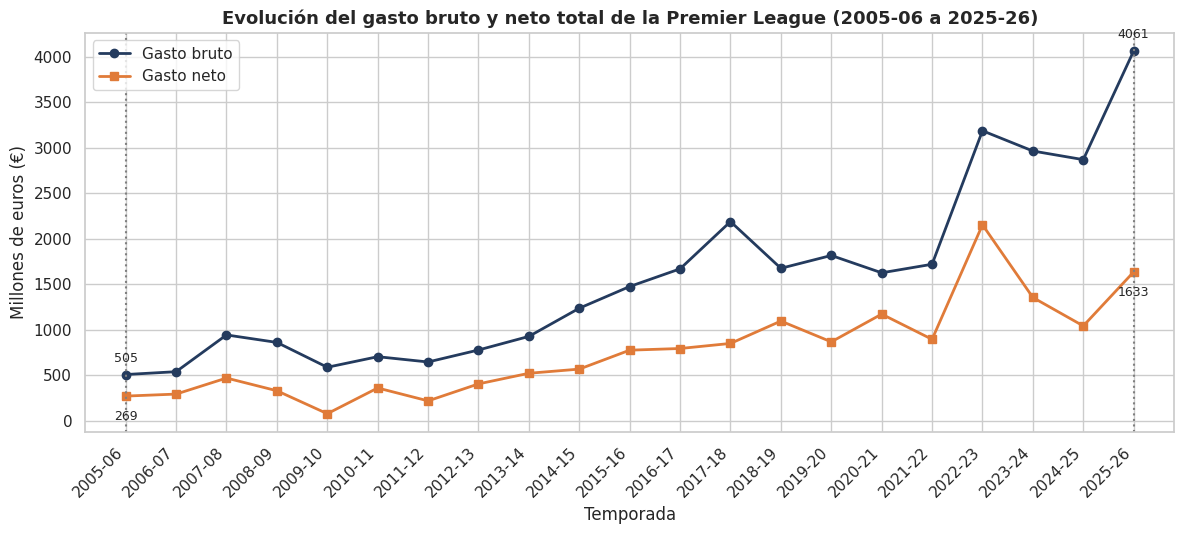

In [12]:
x = np.arange(len(gasto_bruto_temporada))                      # una posición (0 a 20) por cada temporada

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(x, gasto_bruto_temporada.values, marker='o', color=AZUL, lw=2, label='Gasto bruto')
ax.plot(x, gasto_neto_temporada.values, marker='s', color=NARANJA, lw=2, label='Gasto neto')

# Marcamos las dos temporadas de la pregunta de investigación y escribimos sus valores
for pos in [0, len(x) - 1]:
    ax.axvline(pos, color='gray', ls=':', lw=1.5)
    for serie, desplazamiento in [(gasto_bruto_temporada, 9), (gasto_neto_temporada, -17)]:     # bruto: arriba | neto: abajo
        ax.annotate(f"{serie.values[pos]:.0f}", (pos, serie.values[pos]), textcoords='offset points',
                    xytext=(0, desplazamiento), ha='center', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(gasto_bruto_temporada.index, rotation=45, ha='right')
ax.margins(x=0.04)
ax.set_title('Evolución del gasto bruto y neto total de la Premier League (2005-06 a 2025-26)', fontsize=13, fontweight='bold')
ax.set_xlabel('Temporada')
ax.set_ylabel('Millones de euros (€)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('grafico_3_4a_evolucion_gasto.png', dpi=300, bbox_inches='tight')
plt.show()

**Interpretación:** el mercado de pases se encareció de forma muy marcada. El gasto bruto total pasó de 505.45 millones en 2005-06 (el mínimo de la serie) a 4061.22 millones en 2025-26 (el máximo), unas 8 veces más. El gasto neto total pasó de 268.55 a 1633.14 millones (unas 6 veces), con su pico en 2022-23 (2150.87 millones) y no en 2025-26. La distancia entre las dos líneas, que es el dinero que los clubes recuperan vendiendo jugadores, también se agranda con el tiempo.

En el contexto de la pregunta, esto significa que los euros de 2005-06 y los de 2025-26 no son comparables directamente, y que las dos temporadas elegidas son justamente los extremos de la serie de gasto bruto. Por eso, para medir el impacto del gasto sobre la posición usamos medidas relativas dentro de cada temporada (puestos de gasto y grupos de la tabla) y no montos absolutos.

### 3.4.b) Gasto neto por grupo de la tabla
**Tipo de gráfico:** barras agrupadas (comparación entre categorías).
**Qué se hace:** Comparamos el gasto neto promedio de los clubes del Top 4, de la media tabla y de la zona de descenso, con una barra por temporada en cada grupo. Usamos el resumen `resumen_grupos` que calculamos con `groupby` en 3.3.b.
**Por qué:** La pregunta es si el dinero se asocia con la posición. Comparar el gasto de los clubes de arriba, del medio y de abajo en las dos temporadas muestra si los equipos exitosos gastan más y cómo cambió esa diferencia. Las barras son el tipo adecuado porque se compara la altura entre categorías.

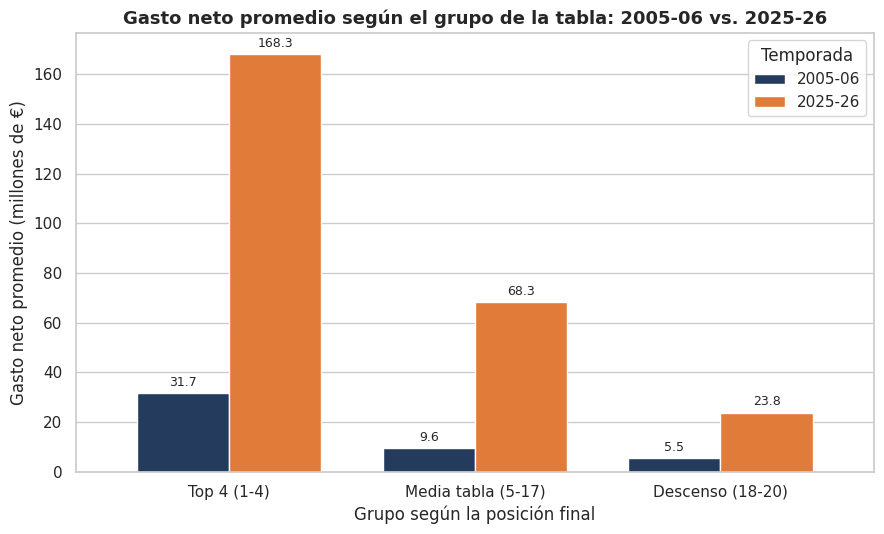

In [13]:
promedios = resumen_grupos['promedio'].unstack(level='temporada')      # filas: grupo de la tabla | columnas: temporada

fig, ax = plt.subplots(figsize=(9, 5.5))
promedios.plot(kind='bar', ax=ax, color=[AZUL, NARANJA], width=0.75, edgecolor='white')
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt='%.1f', padding=3, fontsize=9)         # el valor arriba de cada barra

ax.set_title('Gasto neto promedio según el grupo de la tabla: 2005-06 vs. 2025-26', fontsize=13, fontweight='bold')
ax.set_xlabel('Grupo según la posición final')
ax.set_ylabel('Gasto neto promedio (millones de €)')
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='x', visible=False)                                       # sin líneas verticales detrás de las barras
ax.legend(title='Temporada')
plt.tight_layout()
plt.savefig('grafico_3_4b_gasto_por_grupo.png', dpi=300, bbox_inches='tight')
plt.show()

**Interpretación:** en las dos temporadas el gasto neto promedio baja a medida que se baja en la tabla: el Top 4 gasta más que la media tabla, y esta más que la zona de descenso. Lo que cambia es la escala: en 2005-06 el Top 4 gastó 31.7 millones en promedio y en 2025-26, 168.3. Pero la ventaja relativa del Top 4 sobre la media tabla no creció (3.3 veces en 2005-06 y 2.5 veces en 2025-26).

El gráfico tiene una limitación: son promedios de pocos clubes (4, 13 y 3), así que un solo club los mueve mucho. Por ejemplo, en 2025-26 el Aston Villa, 4º con solo 25.7 millones, baja el promedio del Top 4. Por eso el gráfico 3.4.c muestra a cada club por separado.

### 3.4.c) Relación entre gasto neto y posición final
**Tipo de gráfico:** diagrama de dispersión (relación entre dos variables).
**Qué se hace:** Para cada una de las dos temporadas dibujamos un punto por club, con el gasto neto en el eje horizontal y la posición final en el vertical (invertido, para que el 1º quede arriba). Escribimos en el título cuántos de los 4 clubes que más gastaron terminaron Top 4 y etiquetamos los cuatro clubes con mayor gasto neto y el de menor. Las zonas sombreadas marcan el Top 4 (verde) y el descenso (rojo).
**Por qué:** Es el gráfico que responde directamente a la pregunta de investigación: muestra la relación club por club y permite ver si los puntos se ordenan de arriba a la izquierda hacia abajo a la derecha, y comparar las dos temporadas. Cada panel tiene su propia escala horizontal porque los montos de 2025-26 son varias veces mayores que los de 2005-06.

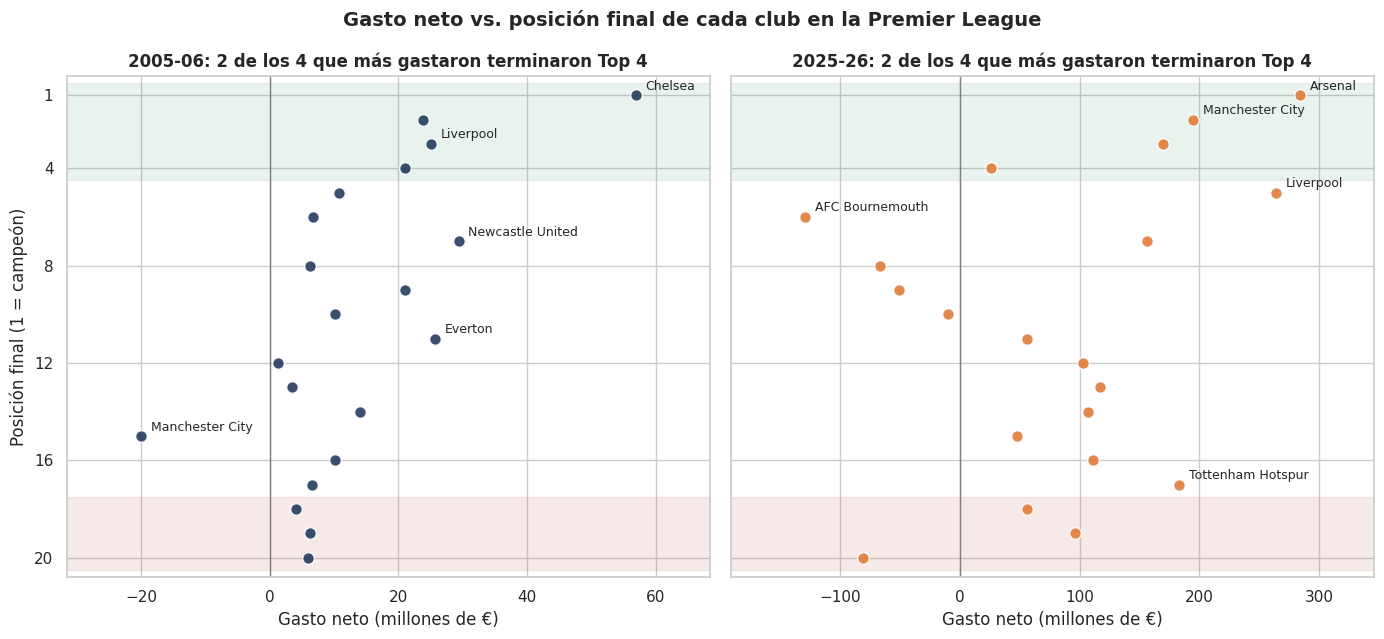

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)
colores = {'2005-06': AZUL, '2025-26': NARANJA}

for ax, temporada in zip(axs, ['2005-06', '2025-26']):
    d = df_estudio[df_estudio['temporada'] == temporada]

    ax.axhspan(0.5, 4.5, color=VERDE, alpha=0.10)                           # zona Top 4
    ax.axhspan(17.5, 20.5, color=ROJO, alpha=0.10)                          # zona de descenso
    ax.axvline(0, color='gray', lw=1)                                       # a la izquierda: vendieron más de lo que compraron
    ax.scatter(d['gasto_neto'], d['posicion'], color=colores[temporada], s=70, alpha=0.9, edgecolor='white', zorder=3)

    # Etiquetamos los 4 clubes con mayor gasto neto y el de menor gasto neto
    destacados = pd.concat([d.nlargest(4, 'gasto_neto'), d.nsmallest(1, 'gasto_neto')])
    for _, fila in destacados.iterrows():
        ax.annotate(fila['club'].replace(' FC', ''), (fila['gasto_neto'], fila['posicion']),
                    textcoords='offset points', xytext=(7, 4), fontsize=9)

    ax.margins(x=0.15)
    aciertos = medidas.loc[temporada, 'aciertos_top4']
    ax.set_title(f"{temporada}: {aciertos} de los 4 que más gastaron terminaron Top 4", fontsize=12, fontweight='bold')
    ax.set_xlabel('Gasto neto (millones de €)')

axs[0].set_ylabel('Posición final (1 = campeón)')
axs[0].set_ylim(20.8, 0.2)                                                  # eje invertido: el 1º arriba
axs[0].set_yticks([1, 4, 8, 12, 16, 20])
fig.suptitle('Gasto neto vs. posición final de cada club en la Premier League', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('grafico_3_4c_dispersion_gasto_posicion.png', dpi=300, bbox_inches='tight')
plt.show()

**Interpretación:** en 2005-06 los puntos bajan de forma bastante ordenada de izquierda a derecha: el club que más gastó en neto, Chelsea, fue campeón, y Liverpool, también entre los 4 que más gastaron, terminó 3º. En 2025-26 también 2 de los 4 que más gastaron terminaron Top 4 (Arsenal 1º y Manchester City 2º), pero la nube está más desordenada: Tottenham, cuarto en gasto neto con 182.9 millones, terminó 17º; Liverpool gastó 263.6 millones y terminó 5º; en cambio, el Aston Villa fue 4º con solo 25.7 millones y el Bournemouth terminó 6º vendiendo más de lo que compró (-129.3 millones).

Es decir, aunque hoy se gasta mucho más dinero, hay más sorpresas que hace 20 años: el gasto neto de una temporada se parece menos al orden final de la tabla. Hay que leerlo con cuidado: es una asociación y no una causa, y el gasto neto de un año no mide los salarios ni el plantel acumulado de temporadas anteriores.

### 3.5. Gráficos de contexto y lectura simple de la relación dinero–posición

**Qué se hace:** Agregamos una sección complementaria que (1) mide la relación entre gasto y posición con preguntas concretas fáciles de entender y (2) suma gráficos de contexto sobre cómo cambió el mercado de pases de la Premier League.
**Por qué:** Para una exposición de 5 a 7 minutos conviene responder con preguntas que cualquiera entiende: *¿el que más gasta, gana? ¿cuántos de los que más gastan terminan arriba? ¿cuántos puestos se equivocó el dinero?*

**Guía rápida de las medidas que usamos:**

| Medida | Qué responde | Valor "por azar" |
|---|---|---|
| **Puesto en gasto** | Lugar que ocupa el club según su gasto neto de esa temporada (1 = el que más gastó) | - |
| **Aciertos Top 4** | De los 4 clubes que más gastaron, ¿cuántos terminaron entre los 4 primeros? | 0.8 de 4 |
| **Posición promedio de los 5 que más gastan** | ¿En qué puesto terminan, en promedio, los 5 que más invierten? | 10.5 |
| **Brecha promedio** | ¿Cuántos puestos, en promedio, separan el puesto de gasto de cada club de su puesto en la tabla? (0 = coinciden exactamente) | 6.7 puestos |

*Asistencia de IA (Claude) en toda la sección 3.5. Prompt: "Quiero un análisis simple pero completo de la relación entre gasto neto y posición, sin correlaciones ni estadística avanzada, con gráficos de contexto para la presentación."*

### 3.5.a) Resumen de medidas simples por temporada

**Qué se hace:** Mostramos la tabla `medidas` (calculada en 3.3.b) para las 21 temporadas y resumimos los promedios.
**Por qué:** Para ver en una sola tabla, temporada por temporada, cuánto se parece el orden de gasto al orden de la tabla, y si 2005-06 y 2025-26 son casos típicos o extremos.

In [15]:
display(medidas)
print(f"Promedio de aciertos en las 21 temporadas: {medidas['aciertos_top4'].mean():.1f} de 4 (por puro azar se esperaría 0.8)")
print(f"Brecha promedio en las 21 temporadas: {medidas['brecha_prom'].mean():.1f} puestos (por puro azar se esperaría 6.7)")
print(f"Campeón fue el club de mayor gasto neto en {(medidas['rank_gasto_campeon'] == 1).sum()} de 21 temporadas")

,aciertos_top4,pos_prom_top5_gasto,brecha_prom,campeon,rank_gasto_campeon
temporada,,,,,
2005-06,2,4.8,4.1,Chelsea FC,1
2006-07,2,7.2,5.1,Manchester United,11
2007-08,1,8.0,6.7,Manchester United,4
2008-09,1,7.4,6.2,Manchester United,4
2009-10,1,6.4,5.9,Chelsea FC,2
2010-11,2,6.4,6.0,Manchester United,10
2011-12,2,6.8,5.4,Manchester City,2
2012-13,2,9.0,6.8,Manchester United,2
2013-14,2,7.0,5.3,Manchester City,1


Promedio de aciertos en las 21 temporadas: 1.5 de 4 (por puro azar se esperaría 0.8)
Brecha promedio en las 21 temporadas: 5.8 puestos (por puro azar se esperaría 6.7)
Campeón fue el club de mayor gasto neto en 4 de 21 temporadas


**Interpretación:** *aciertos_top4* cuenta, de los 4 clubes que más gastaron en neto, cuántos terminaron también entre los 4 primeros. Si el dinero no importara, se esperarían 0.8 aciertos por temporada; si lo decidiera todo, serían 4.

El promedio de las 21 temporadas es de **1.5 aciertos**: casi el doble del azar, pero lejos de 4. Nunca hubo 4 aciertos, solo una temporada tuvo 3 (2014-15) y en dos temporadas (2021-22 y 2024-25) ninguno de los 4 que más gastaron terminó Top 4. La brecha promedio fue de 5.8 puestos, por debajo de los 6.7 del azar en 18 de las 21 temporadas. Además, el campeón fue el club de mayor gasto neto en solo **4 de 21** temporadas (2005-06, 2013-14, 2017-18 y 2025-26). El dinero ayuda, pero ni de cerca decide solo.

### 3.5.b) ¿Cuántos de los que más gastan terminan arriba?

**Tipo de gráfico:** barras (izquierda) y líneas (derecha).
**Qué se hace:** A la izquierda, los aciertos de cada temporada (de los 4 que más gastaron, cuántos terminaron Top 4), con la línea del azar. A la derecha, la posición promedio de los 5 clubes que más gastaron, comparada con 10.5, que es la posición promedio esperable si el gasto no influyera.
**Por qué:** Es la versión sin estadística de la pregunta de investigación. Permite decir en la presentación: "los 4 que más gastaron suelen terminar entre los 4 primeros X de cada 4 veces", y ubicar a 2005-06 y 2025-26 dentro de la serie completa.

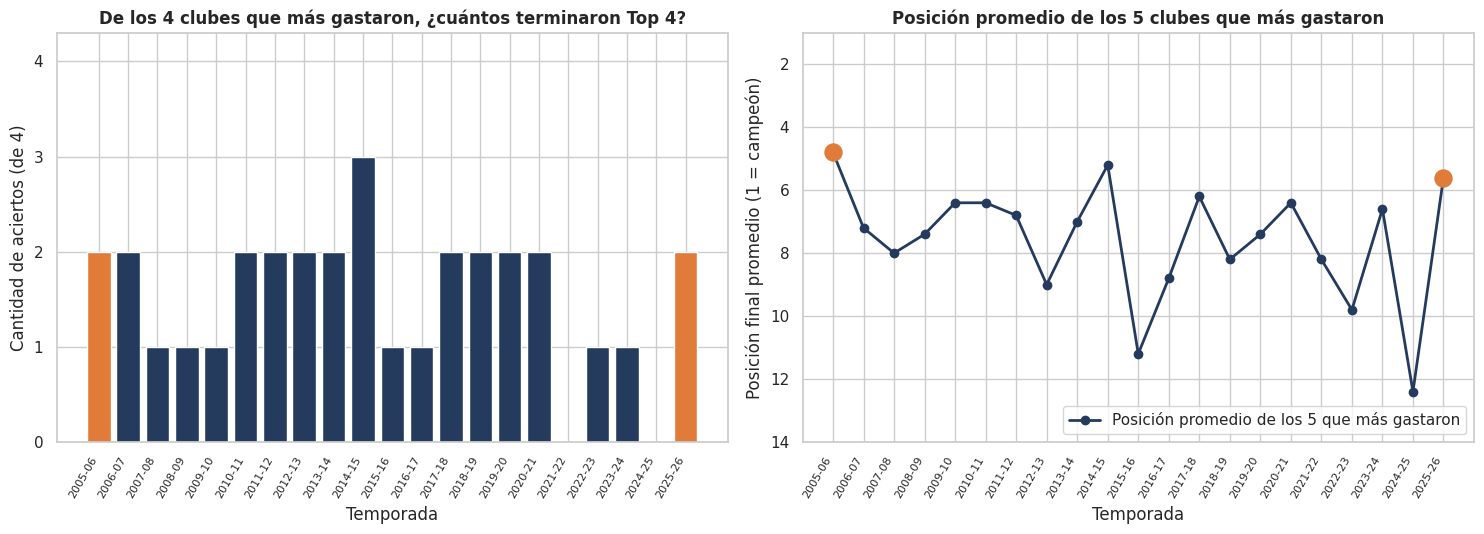

In [21]:
x = np.arange(len(medidas))
etiquetas = list(medidas.index)
destacadas = [etiquetas.index('2005-06'), etiquetas.index('2025-26')]

fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel izquierdo: aciertos
colores_barras = [NARANJA if i in destacadas else AZUL for i in x]
axs[0].bar(x, medidas['aciertos_top4'], color=colores_barras, edgecolor='white')
axs[0].set_ylim(0, 4.3)
axs[0].set_yticks([0, 1, 2, 3, 4])
axs[0].set_xticks(x); axs[0].set_xticklabels(etiquetas, rotation=60, ha='right', fontsize=8)
axs[0].set_title('De los 4 clubes que más gastaron, ¿cuántos terminaron Top 4?', fontsize=12, fontweight='bold')
axs[0].set_xlabel('Temporada'); axs[0].set_ylabel('Cantidad de aciertos (de 4)')

# Panel derecho: posición promedio de los 5 que más gastaron
axs[1].plot(x, medidas['pos_prom_top5_gasto'], marker='o', color=AZUL, lw=2, label='Posición promedio de los 5 que más gastaron')
axs[1].scatter(destacadas, medidas['pos_prom_top5_gasto'].iloc[destacadas], s=150, color=NARANJA, zorder=3)
axs[1].set_ylim(14, 1)    # eje invertido: arriba = mejor posición
axs[1].set_xticks(x); axs[1].set_xticklabels(etiquetas, rotation=60, ha='right', fontsize=8)
axs[1].set_title('Posición promedio de los 5 clubes que más gastaron', fontsize=12, fontweight='bold')
axs[1].set_xlabel('Temporada'); axs[1].set_ylabel('Posición final promedio (1 = campeón)')
axs[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig('grafico_3_5b_aciertos_gasto.png', dpi=300, bbox_inches='tight')
plt.show()

**Interpretación:** *(Naranja = 2005-06 y 2025-26.)* Los 5 clubes que más gastaron terminaron en promedio en el puesto **7.6** (contra 10.5 esperable por azar), y estuvieron mejor ubicados que el azar en 19 de las 21 temporadas. Las únicas excepciones fueron 2015-16 (11.2, el año del título de Leicester) y 2024-25 (12.4).

Para la pregunta de investigación, lo importante es que **con estas medidas simples 2005-06 y 2025-26 se parecen bastante**: ambas tienen 2 aciertos, y los 5 que más gastaron terminaron en promedio 4.8 en 2005-06 y 5.6 en 2025-26. Lo que cambió es que en 2025-26 hubo más sorpresas (Tottenham 17º, Nottingham Forest 16º), que se ven en el gráfico 3.5.e. La conclusión es que la relación se aflojó un poco, pero sin un cambio dramático.

### 3.5.c) ¿Ganó el que más gastó?

**Tipo de gráfico:** puntos conectados por línea.
**Qué se hace:** Para cada temporada mostramos en qué puesto de gasto neto estaba el campeón (1 = el club que más gastó).
**Por qué:** Es la forma más directa de contar la historia: ¿el título lo gana quien más invierte en el mercado de pases, o hay campeones que ganaron gastando poco en neto?

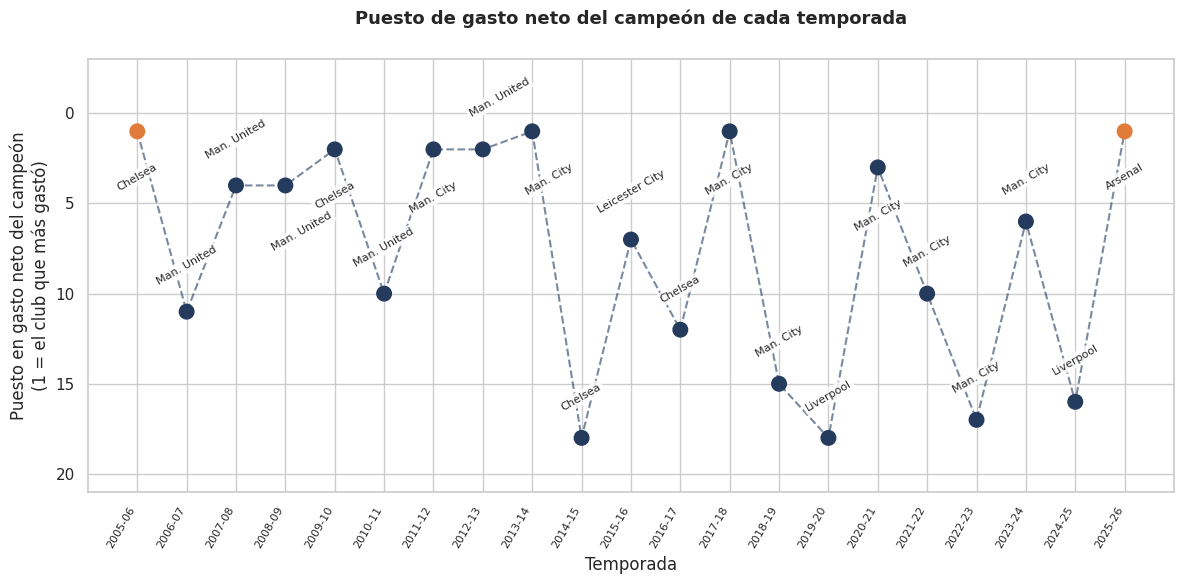

In [24]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(x, medidas['rank_gasto_campeon'], marker='o', color=AZUL, lw=1.5, ls='--', alpha=0.6)
colores_pts = [NARANJA if i in destacadas else AZUL for i in x]
ax.scatter(x, medidas['rank_gasto_campeon'], s=110, color=colores_pts, zorder=3)

# Para controlar colisiones, almacenamos las posiciones de las etiquetas que ya dibujamos
posiciones_dibujadas = []

for i, (t, fila) in enumerate(medidas.iterrows()):
    rank = fila['rank_gasto_campeon']
    nombre = fila['campeon'].replace(' FC', '').replace('Manchester ', 'Man. ')

    # Configuración base
    desplazamiento_y = -22 if rank <= 3 else 18
    desplazamiento_x = 0
    va_val = 'top' if rank <= 3 else 'bottom'

    # Algoritmo simple anti-colisión con etiquetas adyacentes
    for prev_x, prev_y, prev_desp_x, prev_desp_y in posiciones_dibujadas:
        if abs(i - prev_x) <= 1.2 and abs(rank - prev_y) <= 1.5:
            # Si están muy cerca, empujamos la etiqueta actual en dirección opuesta o desfasamos en X
            if desplazamiento_y == prev_desp_y:
                desplazamiento_y = -desplazamiento_y  # Invertir verticalmente
                va_val = 'bottom' if va_val == 'top' else 'top'
            # Agregar desplazamiento en X para evitar solape lateral por la rotación de 30°
            desplazamiento_x = 12 if (i > prev_x) else -12

    # Registrar posición final aproximada de esta etiqueta para el siguiente chequeo
    posiciones_dibujadas.append((i, rank, desplazamiento_x, desplazamiento_y))

    ax.annotate(nombre,
                (i, rank),
                textcoords='offset points',
                xytext=(desplazamiento_x, desplazamiento_y),
                ha='center',
                va=va_val,
                fontsize=8,
                rotation=30,
                zorder=4,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.85, ec='none'))

# Le damos más aire arriba (valores cercanos a 0 en el eje invertido) para que no choque con el título
ax.set_ylim(max(medidas['rank_gasto_campeon']) + 3, -3)    # invertido: 1 (mayor gasto) arriba
ax.set_xticks(x); ax.set_xticklabels(etiquetas, rotation=60, ha='right', fontsize=8)
ax.set_title('Puesto de gasto neto del campeón de cada temporada', fontsize=13, fontweight='bold', pad=25)
ax.set_xlabel('Temporada'); ax.set_ylabel('Puesto en gasto neto del campeón\n(1 = el club que más gastó)')
plt.tight_layout()
plt.savefig('grafico_3_5c_campeon_gasto.png', dpi=300, bbox_inches='tight')
plt.show()

**Interpretación:** El campeón fue el mayor gastador neto en 4 de 21 temporadas, estuvo entre los 3 primeros en gasto en 8 y entre los 5 primeros en 10. En las otras 11 ganó con un gasto neto de la mitad de la tabla hacia abajo, algo notable en casos como Chelsea 2014-15 (18º en gasto neto), Liverpool 2019-20 (18º), Manchester City 2022-23 (17º) y Liverpool 2024-25 (16º). Hay que leerlo con cuidado: el gasto neto resta lo que se vende, y esos clubes tenían plantel y salarios muy altos construidos en años anteriores. Esto refuerza la cautela de que el gasto neto de una temporada no mide el poder económico total del club.

### 3.5.d) Contexto del mercado: concentración del gasto y autofinanciamiento

**Tipo de gráfico:** líneas (izquierda) y barras (derecha).
**Qué se hace:** A la izquierda, qué porcentaje del gasto bruto total de la liga hace el grupo de los 6 clubes que más gastan en cada temporada. A la derecha, cuántos de los 20 clubes terminaron la temporada con superávit (vendieron más de lo que compraron, es decir, gasto neto negativo).
**Por qué:** Responde al contexto de la hipercomercialización: ¿el dinero se concentró en pocos clubes? ¿Cambió la estrategia de los clubes, que hoy financian sus compras vendiendo jugadores?

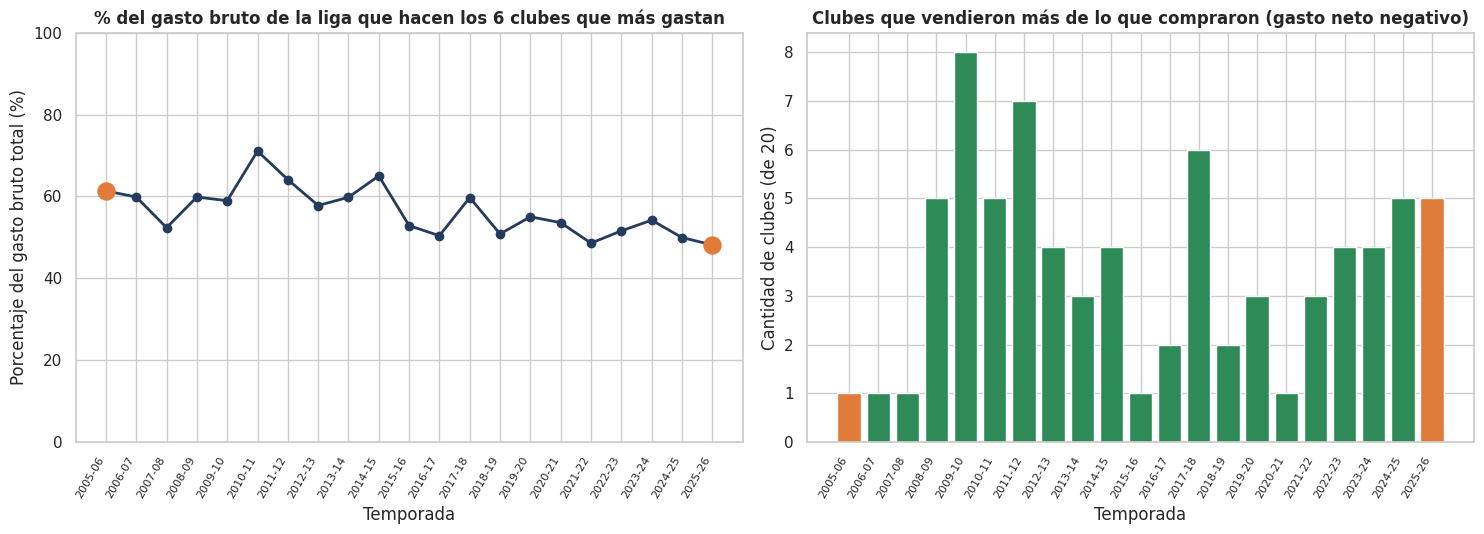

In [18]:
concentracion = pd.Series({t: d.nlargest(6, 'gasto_bruto')['gasto_bruto'].sum() / d['gasto_bruto'].sum() * 100
                           for t, d in df_completo.groupby('temporada')})
clubes_superavit = df_completo.groupby('temporada')['gasto_neto'].apply(lambda s: (s < 0).sum())

fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))

axs[0].plot(x, concentracion.values, marker='o', color=AZUL, lw=2)
axs[0].scatter(destacadas, concentracion.iloc[destacadas], s=150, color=NARANJA, zorder=3)
axs[0].set_xticks(x); axs[0].set_xticklabels(etiquetas, rotation=60, ha='right', fontsize=8)
axs[0].set_title('% del gasto bruto de la liga que hacen los 6 clubes que más gastan', fontsize=12, fontweight='bold')
axs[0].set_xlabel('Temporada'); axs[0].set_ylabel('Porcentaje del gasto bruto total (%)')
axs[0].set_ylim(0, 100)

axs[1].bar(x, clubes_superavit.values, color=[NARANJA if i in destacadas else VERDE for i in x], edgecolor='white')
axs[1].set_xticks(x); axs[1].set_xticklabels(etiquetas, rotation=60, ha='right', fontsize=8)
axs[1].set_title('Clubes que vendieron más de lo que compraron (gasto neto negativo)', fontsize=12, fontweight='bold')
axs[1].set_xlabel('Temporada'); axs[1].set_ylabel('Cantidad de clubes (de 20)')

plt.tight_layout()
plt.savefig('grafico_3_5d_concentracion_superavit.png', dpi=300, bbox_inches='tight')
plt.show()

**Interpretación:** Contra lo que se podría esperar, la concentración del gasto **no aumentó**: los 6 clubes que más gastan hacían el 61.4% del gasto bruto en 2005-06 y el 48.2% en 2025-26 (mínimo de la serie; el máximo fue 71.1% en 2010-11). Es decir, el mercado se encareció muchísimo pero el dinero se repartió entre más clubes. A la vez, los clubes con superávit pasaron de 1 en 2005-06 a 5 en 2025-26 (con picos de 7 y 8 en 2011-12 y 2009-10). Que más clubes financien su plantel vendiendo jugadores, y que el gasto esté más repartido, ayuda a explicar por qué el gasto neto de una temporada se parece menos al orden de la tabla que hace 20 años (brecha promedio de 4.1 puestos en 2005-06 y 5.3 en 2025-26).

### 3.5.e) Club por club: puesto de gasto vs. puesto en la tabla

**Tipo de gráfico:** dumbbell (dos puntos unidos por una línea para cada club).
**Qué se hace:** Para 2005-06 y 2025-26, cada club aparece en una fila ordenada por su posición final. El punto azul es su puesto en la tabla y el punto naranja su puesto en gasto neto. Cuanto más larga la línea, mayor la diferencia entre lo que gastó y lo que logró. En el título de cada panel figura la *brecha promedio*: cuántos puestos, en promedio, separan a un club de donde lo ubicaba su gasto.
**Por qué:** Es un gráfico muy fácil de explicar oralmente y muestra los casos concretos: quiénes rindieron mucho más de lo que gastaron y quiénes decepcionaron con mucho gasto.

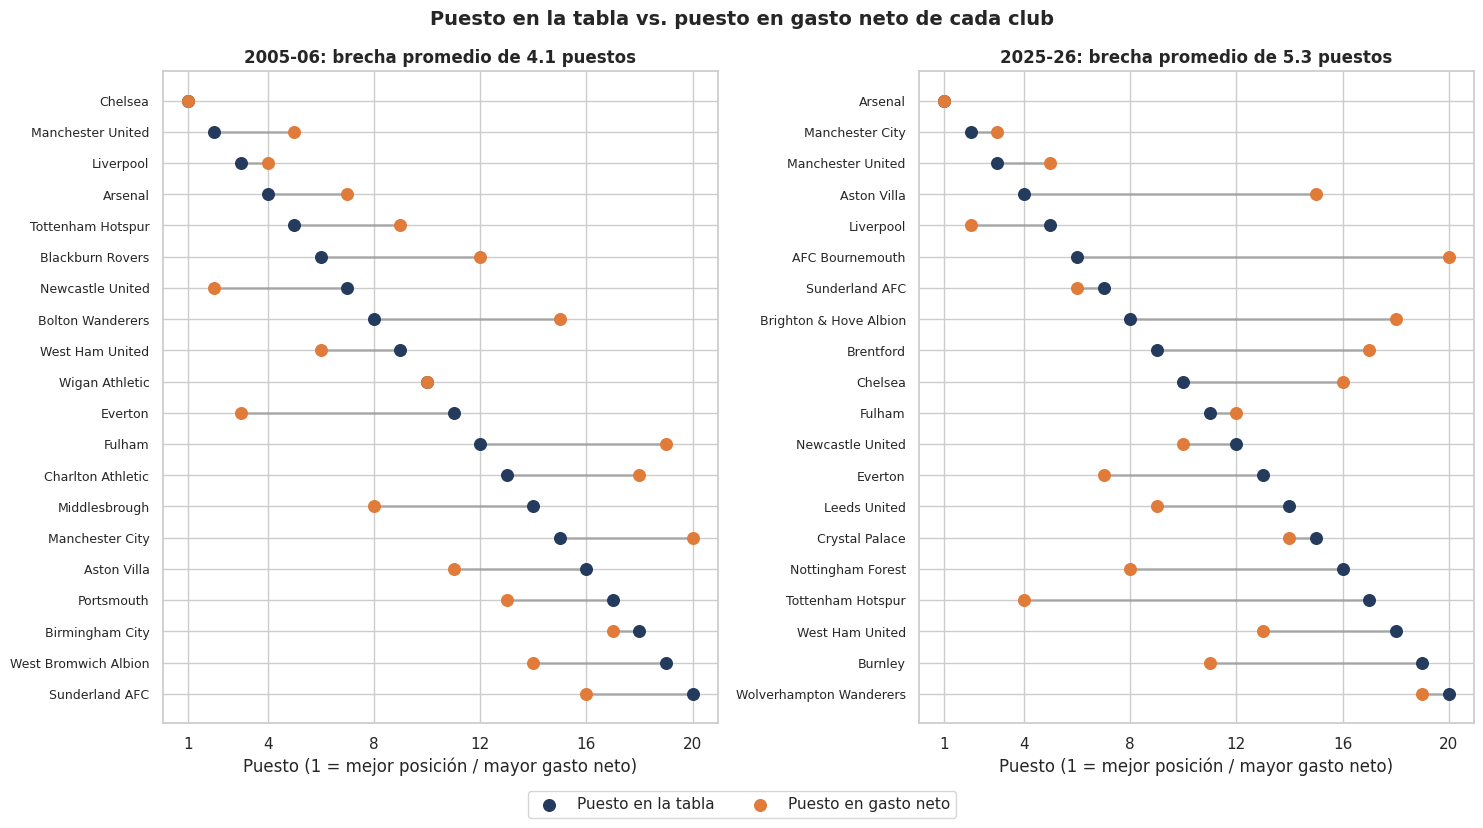

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(15, 8), sharex=True)

for ax, temporada in zip(axs, ['2005-06', '2025-26']):
    d = df_completo[df_completo['temporada'] == temporada].sort_values('posicion')
    y = np.arange(len(d))
    ax.hlines(y, d['posicion'], d['rank_gasto'], color='gray', alpha=0.5, lw=2)
    ax.scatter(d['posicion'], y, color=AZUL, s=70, zorder=3, label='Puesto en la tabla')
    ax.scatter(d['rank_gasto'], y, color=NARANJA, s=70, zorder=3, label='Puesto en gasto neto')
    ax.set_yticks(y); ax.set_yticklabels(d['club'].str.replace(' FC', ''), fontsize=9)
    ax.set_xticks([1, 4, 8, 12, 16, 20])
    ax.invert_yaxis()
    ax.set_title(f"{temporada}: brecha promedio de {medidas.loc[temporada, 'brecha_prom']} puestos", fontsize=12, fontweight='bold')
    ax.set_xlabel('Puesto (1 = mejor posición / mayor gasto neto)')

fig.legend(*axs[0].get_legend_handles_labels(), loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.04), fontsize=11)
fig.suptitle('Puesto en la tabla vs. puesto en gasto neto de cada club', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('grafico_3_5e_dumbbell_gasto_posicion.png', dpi=300, bbox_inches='tight')
plt.show()

**Interpretación:** En 2005-06 las líneas son más cortas (brecha promedio de 4.1 puestos, la más chica de las 21 temporadas): Everton fue 3º en gasto y terminó 11º, y Fulham y Bolton gastaron poco (19º y 15º) y terminaron 12º y 8º. En 2025-26 hay brechas más grandes (5.3 puestos en promedio): Bournemouth fue 20º en gasto neto y terminó 6º (14 puestos mejor), Aston Villa 15º en gasto y 4º en la tabla (11 puestos) y Brighton 18º y 8º. En el otro extremo, Tottenham fue 4º en gasto y terminó 17º (13 puestos peor), seguido por Nottingham Forest y Burnley. Aun así, el campeón Arsenal fue el club de mayor gasto neto, así que el dinero sigue pesando en la cima.

### 3.5.f) Visión de largo plazo: gasto acumulado de 21 años y posición promedio

**Tipo de gráfico:** barras horizontales.
**Qué se hace:** Para los clubes que jugaron al menos 10 de las 21 temporadas, sumamos todo su gasto neto del período y calculamos su posición promedio. Cada barra es el gasto acumulado; al lado de la barra escribimos la posición promedio del club. Las barras azules son los clubes con posición promedio de 7 o mejor.
**Por qué:** El gasto de una sola temporada no incluye el plantel construido en años anteriores. Sumando varios años, el dinero tiene más chances de mostrar su efecto. La pregunta que responde es simple: *¿los clubes que más gastaron durante 21 años son los que mejor terminaron en promedio?* Los montos están en euros de cada año (sin ajustar por inflación), pero como se comparan clubes entre sí, la inflación afecta a todos por igual.

,temporadas,gasto_neto_acum,posicion_prom
club,,,
Manchester City,21,1926.1,3.9
Manchester United,21,1801.4,3.9
Chelsea FC,21,1446.0,4.1
Arsenal FC,21,1230.7,3.9
Tottenham Hotspur,21,1030.0,6.4
Liverpool FC,21,977.1,4.1
Newcastle United,19,762.5,11.2
West Ham United,20,703.4,12.0
Aston Villa,18,548.6,11.1


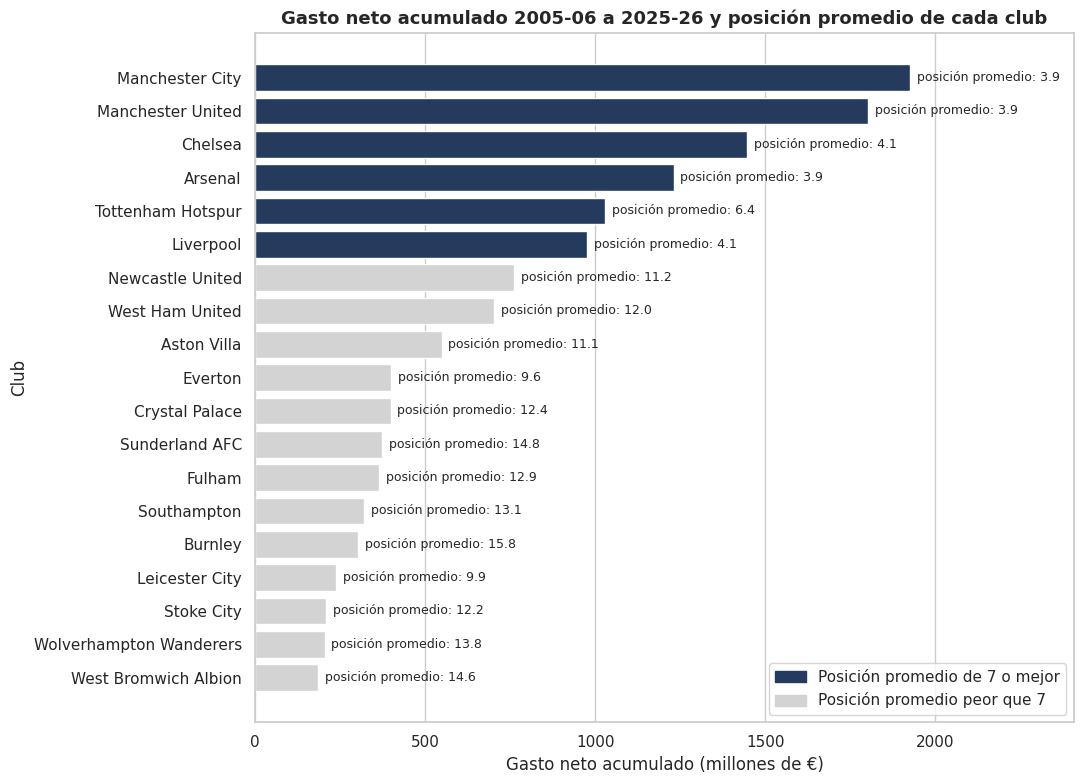

In [20]:
from matplotlib.patches import Patch

largo_plazo = (df_completo.groupby('club')
               .agg(temporadas=('temporada', 'count'),
                    gasto_neto_acum=('gasto_neto', 'sum'),
                    posicion_prom=('posicion', 'mean'))
               .query('temporadas >= 10')
               .sort_values('gasto_neto_acum'))
display(largo_plazo.round(1).sort_values('gasto_neto_acum', ascending=False))

clubes = largo_plazo.index.str.replace(' FC', '')
colores = [AZUL if p <= 7 else 'lightgray' for p in largo_plazo['posicion_prom']]

fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(clubes, largo_plazo['gasto_neto_acum'], color=colores, edgecolor='white')
for y, (gasto, pos) in enumerate(zip(largo_plazo['gasto_neto_acum'], largo_plazo['posicion_prom'])):
    ax.text(gasto + 20, y, f"posición promedio: {pos:.1f}", va='center', fontsize=9)
ax.set_xlim(0, largo_plazo['gasto_neto_acum'].max() * 1.25)
ax.set_title('Gasto neto acumulado 2005-06 a 2025-26 y posición promedio de cada club', fontsize=13, fontweight='bold')
ax.set_xlabel('Gasto neto acumulado (millones de €)')
ax.set_ylabel('Club')
ax.grid(axis='y', visible=False)
ax.legend(handles=[Patch(color=AZUL, label='Posición promedio de 7 o mejor'), Patch(color='lightgray', label='Posición promedio peor que 7')], loc='lower right')
plt.tight_layout()
plt.savefig('grafico_3_5f_largo_plazo.png', dpi=300, bbox_inches='tight')
plt.show()

**Interpretación:** Los 6 clubes que más gastaron en neto durante los 21 años (Manchester City, Manchester United, Chelsea, Arsenal, Tottenham y Liverpool) son también los 6 con mejor posición promedio, entre 3.9 y 6.4. Los demás clubes, con menos gasto acumulado, tienen posiciones promedio de 9.6 a 15.8.

Entonces: **el gasto de un año predice poco, pero el gasto sostenido en el tiempo sí distingue a los clubes que terminan arriba.** Hay excepciones que lo matizan: Leicester (237 millones, posición promedio 9.9) y Everton (400 millones, 9.6) rindieron más de lo que gastaron, mientras que Newcastle (763 millones, 11.2) y West Ham (703 millones, 12.0) rindieron menos. Dos cautelas: (1) el grupo de seis grandes es el que marca la diferencia, y (2) sigue siendo una asociación y no prueba causalidad: los clubes con más hinchas e ingresos también pueden gastar más.